# NSL-KDD: Exploratory Data Analysis

**Goal:** understand the NSL-KDD intrusion-detection data before modelling. That covers its structure and quality, class balance,
how the features behave, and how the **test distribution differs from training**. That last point matters most for this dataset.

Splits: `KDDTrain+` (125,973 rows), `KDDTest+` (22,544 rows), `KDDTest-21` (11,850 harder rows).

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import ks_2samp
from sklearn.feature_selection import mutual_info_classif
from src.data import load_all, FEATURES, CATEGORICAL, NUMERIC, CLASSES

sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.dpi"] = 110
FIG = "../reports/figures/"
pd.set_option("display.max_columns", 50)

train, test, test21 = load_all()
print("train", train.shape, "| test", test.shape, "| test-21", test21.shape)
train.head()

train (125973, 45) | test (22544, 45) | test-21 (11850, 45)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty,category,is_attack
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20,Normal,0
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15,Normal,0
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19,DoS,1
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21,Normal,0
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21,Normal,0


## 1. Structure and data quality

In [2]:
info = pd.DataFrame({
    "dtype": train[FEATURES].dtypes.astype(str),
    "n_unique": train[FEATURES].nunique(),
    "n_missing": train[FEATURES].isna().sum(),
    "pct_zero": (train[FEATURES] == 0).mean().round(3),
})
info

,dtype,n_unique,n_missing,pct_zero
duration,int64,2981,0,0.920
protocol_type,str,3,0,0.000
service,str,70,0,0.000
flag,str,11,0,0.000
src_bytes,int64,3341,0,0.392
dst_bytes,int64,9326,0,0.540
land,int64,2,0,1.000
wrong_fragment,int64,3,0,0.991
urgent,int64,4,0,1.000
hot,int64,28,0,0.979


In [3]:
dup = train.duplicated(subset=FEATURES).sum()
conflict = train.groupby(FEATURES).category.nunique().gt(1).sum()
constant = [c for c in NUMERIC if train[c].nunique() <= 1]
print(f"Missing values (all splits): {train.isna().sum().sum() + test.isna().sum().sum()}")
print(f"Duplicate feature rows in train: {dup}  ({conflict} with conflicting labels)")
print(f"Constant columns: {constant}")
mostly_zero = info[info.pct_zero > 0.99].index.tolist()
print(f"Columns that are >99% zero: {mostly_zero}")

Missing values (all splits): 0
Duplicate feature rows in train: 16  (7 with conflicting labels)
Constant columns: ['num_outbound_cmds']
Columns that are >99% zero: ['land', 'wrong_fragment', 'urgent', 'num_failed_logins', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login']


## 2. Target distribution

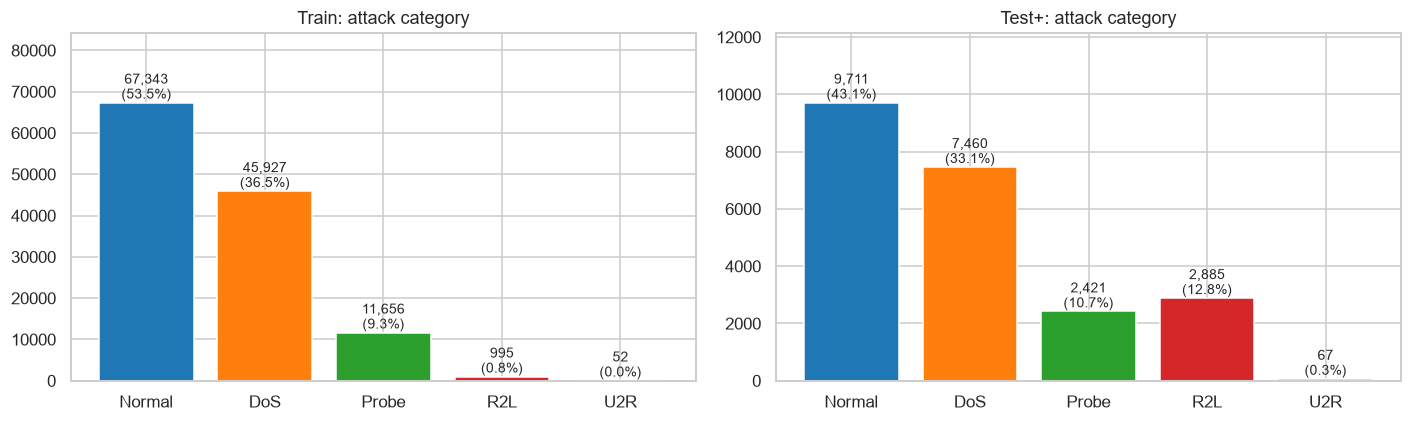

,train,test+,test-21
category,,,
Normal,53.46,43.08,18.16
DoS,36.46,33.09,36.66
Probe,9.25,10.74,20.27
R2L,0.79,12.80,24.35
U2R,0.04,0.30,0.57


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, df) in zip(axes, [("Train", train), ("Test+", test)]):
    vc = df.category.value_counts().reindex(CLASSES)
    ax.bar(vc.index, vc.values, color=sns.color_palette("tab10", 5))
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"{name}: attack category"); ax.set_ylim(0, vc.max() * 1.25)
plt.tight_layout(); plt.savefig(FIG + "class_distribution.png", bbox_inches="tight"); plt.show()

dist = pd.concat([train.category.value_counts(normalize=True).rename("train"),
                  test.category.value_counts(normalize=True).rename("test+"),
                  test21.category.value_counts(normalize=True).rename("test-21")], axis=1).reindex(CLASSES)
(dist * 100).round(2)

In [5]:
# Attack-level counts and the attack types that appear only in test
lab = pd.concat([train.label.value_counts().rename("train"), test.label.value_counts().rename("test+")], axis=1).fillna(0).astype(int)
lab["category"] = lab.index.map(dict(zip(pd.concat([train, test]).label, pd.concat([train, test]).category)))
lab["unseen_in_train"] = lab.train.eq(0)
unseen = lab[lab.unseen_in_train]
print(f"{len(unseen)} attack types appear only in test, covering {unseen['test+'].sum():,} rows "
      f"({unseen['test+'].sum()/len(test):.1%} of Test+)")
lab.sort_values(["category", "train"], ascending=[True, False])

17 attack types appear only in test, covering 3,750 rows (16.6% of Test+)


,train,test+,category,unseen_in_train
label,,,,
neptune,41214,4657,DoS,False
smurf,2646,665,DoS,False
back,956,359,DoS,False
teardrop,892,12,DoS,False
pod,201,41,DoS,False
land,18,7,DoS,False
apache2,0,737,DoS,True
processtable,0,685,DoS,True
mailbomb,0,293,DoS,True


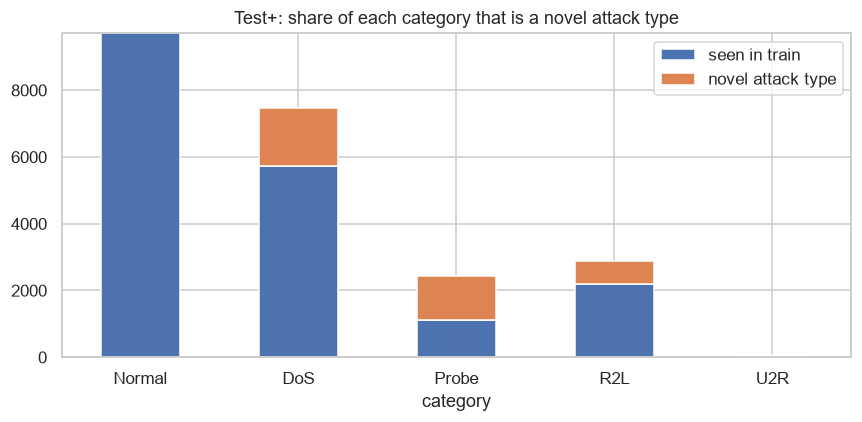

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
novel = test.assign(novel=~test.label.isin(train.label.unique()))
pd.crosstab(novel.category, novel.novel).reindex(CLASSES).plot.bar(stacked=True, ax=ax, color=["#4C72B0", "#DD8452"])
ax.legend(["seen in train", "novel attack type"]); ax.set_title("Test+: share of each category that is a novel attack type")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIG + "novel_attacks.png", bbox_inches="tight"); plt.show()

### Difficulty level
Each row has a difficulty score: the number of 21 reference classifiers that labelled it correctly. Lower means harder.

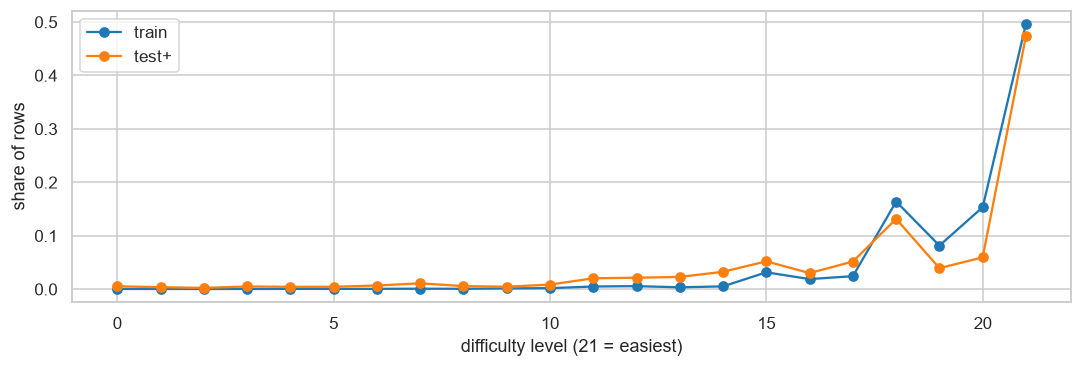

Rows with difficulty <= 15 -> train: 6.1%  test+: 21.3%


In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for name, df in [("train", train), ("test+", test)]:
    df.difficulty.value_counts(normalize=True).sort_index().plot(ax=ax, marker="o", label=name)
ax.set_xlabel("difficulty level (21 = easiest)"); ax.set_ylabel("share of rows"); ax.legend()
plt.tight_layout(); plt.show()
print("Rows with difficulty <= 15 -> train: {:.1%}  test+: {:.1%}".format((train.difficulty <= 15).mean(), (test.difficulty <= 15).mean()))

## 3. Categorical features

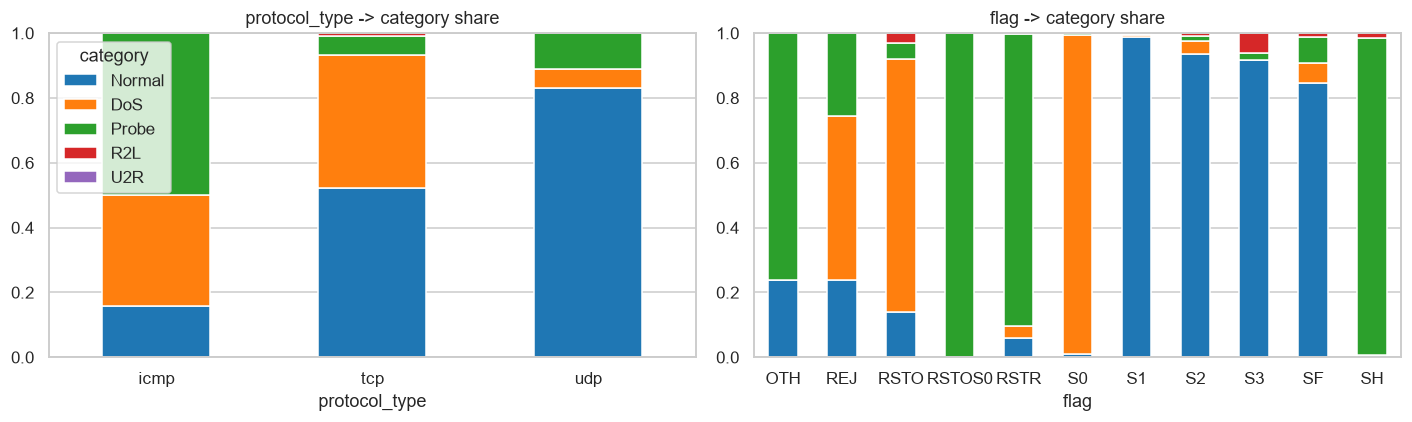

category,Normal,DoS,Probe,R2L,U2R
flag,,,,,
OTH,11,0,35,0,0
REJ,2693,5671,2869,0,0
RSTO,219,1216,80,46,1
RSTOS0,0,0,103,0,0
RSTR,146,90,2180,5,0
S0,354,34344,153,0,0
S1,361,2,1,1,0
S2,119,5,2,1,0
S3,45,0,1,3,0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.crosstab(train.protocol_type, train.category, normalize="index")[CLASSES].plot.bar(stacked=True, ax=axes[0])
axes[0].set_title("protocol_type -> category share"); axes[0].tick_params(axis="x", rotation=0)
pd.crosstab(train.flag, train.category, normalize="index")[CLASSES].plot.bar(stacked=True, ax=axes[1], legend=False)
axes[1].set_title("flag -> category share"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIG + "protocol_flag.png", bbox_inches="tight"); plt.show()
pd.crosstab(train.flag, train.category)[CLASSES]

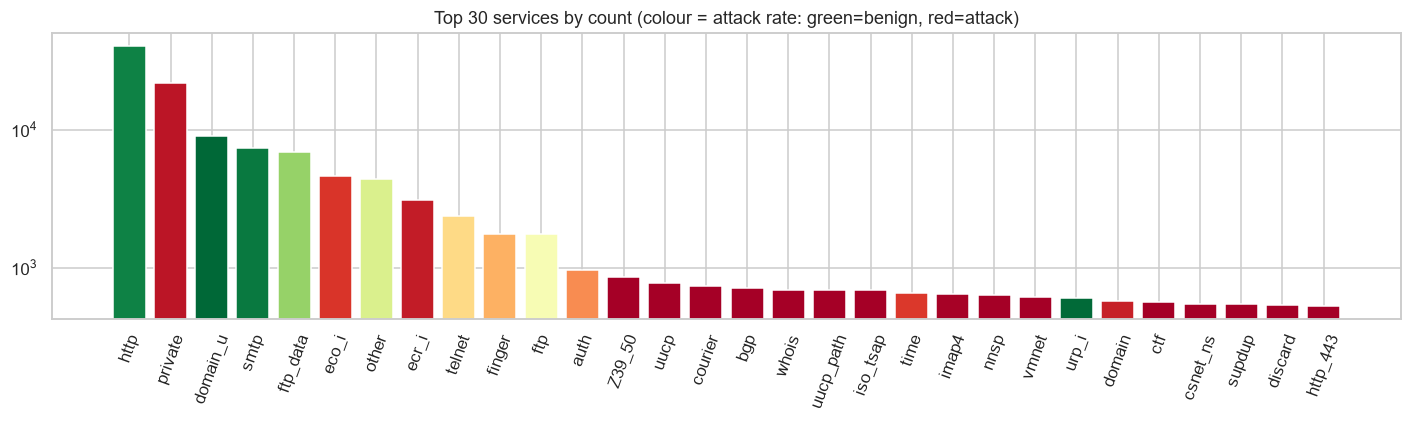

70 services; 9 have fewer than 20 rows; 48 are 100% normal or 100% attack


service,http,private,domain_u,smtp,ftp_data,eco_i,other,ecr_i,telnet,finger,ftp,auth,Z39_50,uucp,courier
n,40338.000000,21853.000000,9043.000000,7313.000000,6860.000000,4586.000000,4359.000000,3077.000000,2353.000000,1767.000000,1754.000000,955.00000,862.0,780.0,734.0
attack_rate,0.056746,0.955063,0.000995,0.038835,0.273469,0.891627,0.402615,0.938252,0.610285,0.691568,0.476625,0.75288,1.0,1.0,1.0


In [9]:
svc = train.groupby("service").agg(n=("is_attack", "size"), attack_rate=("is_attack", "mean")).sort_values("n", ascending=False)
fig, ax = plt.subplots(figsize=(13, 4))
top = svc.head(30)
ax.bar(top.index, top.n, color=plt.cm.RdYlGn_r(top.attack_rate))
ax.set_yscale("log"); ax.set_title("Top 30 services by count (colour = attack rate: green=benign, red=attack)")
plt.xticks(rotation=70); plt.tight_layout(); plt.savefig(FIG + "services.png", bbox_inches="tight"); plt.show()
print(f"{train.service.nunique()} services; {(svc.n < 20).sum()} have fewer than 20 rows; "
      f"{(svc.attack_rate.isin([0, 1])).sum()} are 100% normal or 100% attack")
svc.head(15).T

## 4. Numeric features: distributions and skew

In [10]:
desc = train[NUMERIC].describe().T
desc["skew"] = train[NUMERIC].skew()
desc.sort_values("skew", ascending=False).round(3)

,count,mean,std,min,25%,50%,75%,max,skew
is_host_login,125973.0,0.000,0.003,0.0,0.00,0.00,0.00,1.000000e+00,354.927
dst_bytes,125973.0,19779.114,4021269.151,0.0,0.00,0.00,516.00,1.309937e+09,290.053
num_compromised,125973.0,0.279,23.942,0.0,0.00,0.00,0.00,7.479000e+03,250.108
num_root,125973.0,0.302,24.400,0.0,0.00,0.00,0.00,7.468000e+03,236.914
src_bytes,125973.0,45566.743,5870331.182,0.0,0.00,44.00,276.00,1.379964e+09,190.669
urgent,125973.0,0.000,0.014,0.0,0.00,0.00,0.00,3.000000e+00,149.915
land,125973.0,0.000,0.014,0.0,0.00,0.00,0.00,1.000000e+00,70.965
num_shells,125973.0,0.000,0.022,0.0,0.00,0.00,0.00,2.000000e+00,59.592
num_file_creations,125973.0,0.013,0.484,0.0,0.00,0.00,0.00,4.300000e+01,55.665
num_failed_logins,125973.0,0.001,0.045,0.0,0.00,0.00,0.00,5.000000e+00,53.764


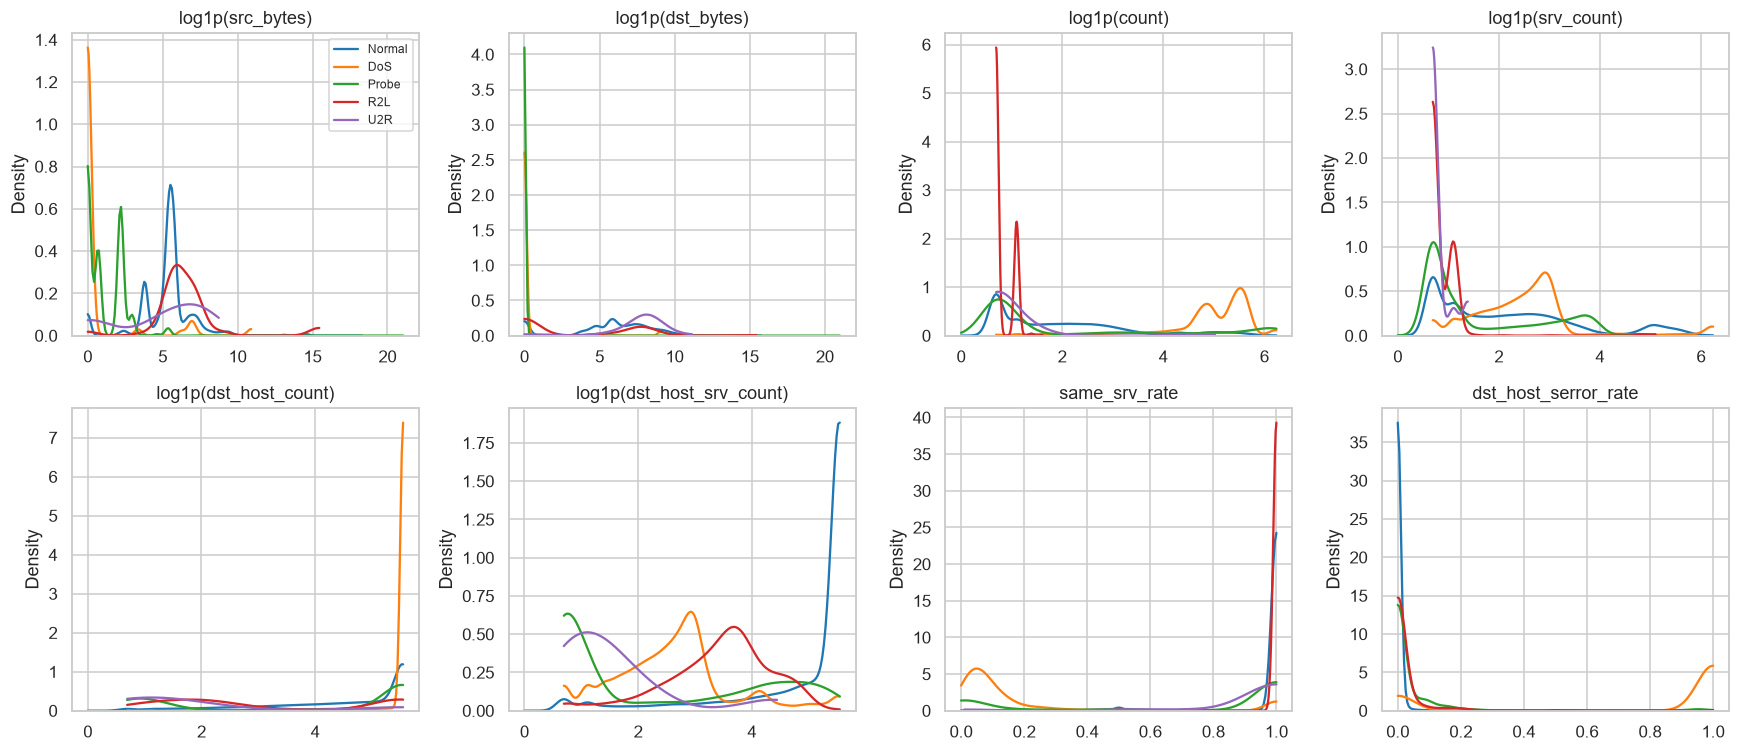

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, ["src_bytes", "dst_bytes", "count", "srv_count", "dst_host_count", "dst_host_srv_count", "same_srv_rate", "dst_host_serror_rate"]):
    for cat in CLASSES:
        v = train.loc[train.category == cat, c]
        v = v if "rate" in c else np.log1p(v)
        sns.kdeplot(v, ax=ax, label=cat, warn_singular=False, cut=0, common_norm=False)
    ax.set_title(f"log1p({c})" if "rate" not in c else c); ax.set_xlabel("")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG + "numeric_kde.png", bbox_inches="tight"); plt.show()

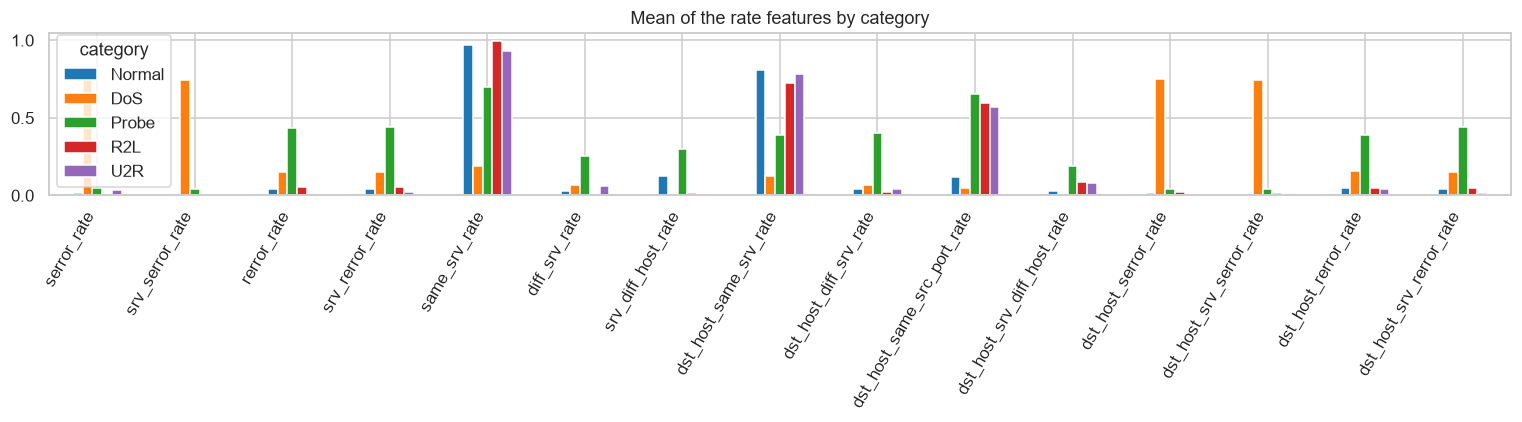

In [12]:
rate_cols = [c for c in NUMERIC if "rate" in c]
fig, ax = plt.subplots(figsize=(14, 4))
train.groupby("category")[rate_cols].mean().reindex(CLASSES).T.plot.bar(ax=ax)
ax.set_title("Mean of the rate features by category"); plt.xticks(rotation=60, ha="right")
plt.tight_layout(); plt.savefig(FIG + "rate_features.png", bbox_inches="tight"); plt.show()

## 5. Feature relevance: mutual information with the target

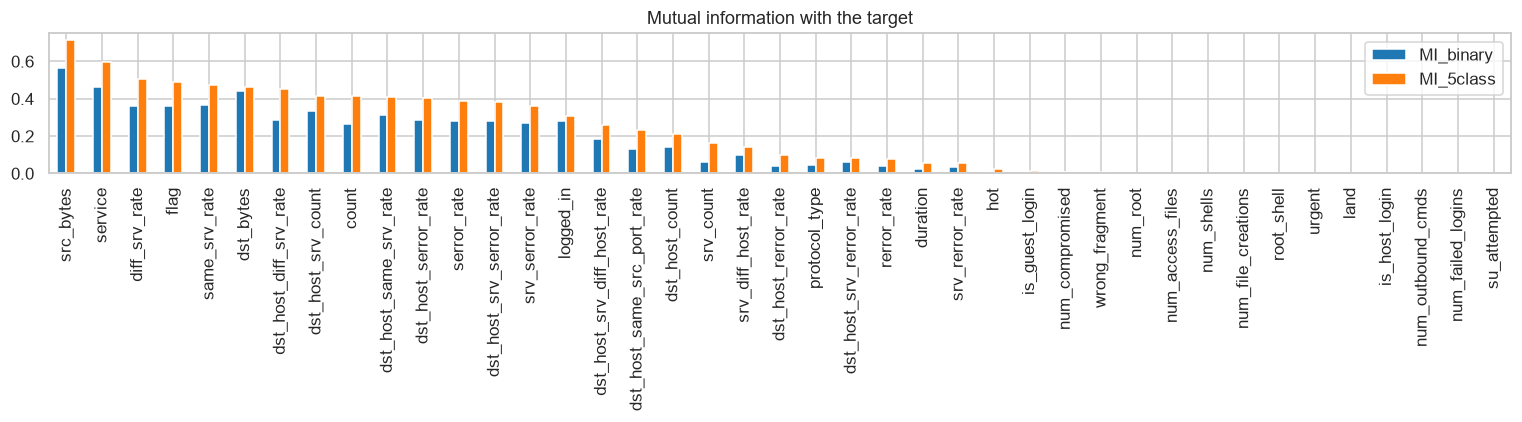

Near-zero MI (<0.001): ['land', 'is_host_login', 'num_outbound_cmds', 'num_failed_logins', 'su_attempted']


,MI_binary,MI_5class
src_bytes,0.5665,0.7158
service,0.4655,0.5962
diff_srv_rate,0.3602,0.5071
flag,0.3600,0.4892
same_srv_rate,0.3687,0.4737
dst_bytes,0.4409,0.4605
dst_host_diff_srv_rate,0.2853,0.4513
dst_host_srv_count,0.3354,0.4171
count,0.2636,0.4126
dst_host_same_srv_rate,0.3113,0.4069


In [13]:
X = train[FEATURES].copy()
for c in CATEGORICAL:
    X[c] = X[c].astype("category").cat.codes
disc = [c in CATEGORICAL or c in ("land", "logged_in", "root_shell", "is_host_login", "is_guest_login") for c in FEATURES]
mi_bin = mutual_info_classif(X, train.is_attack, discrete_features=disc, random_state=0)
mi_cat = mutual_info_classif(X, train.category, discrete_features=disc, random_state=0)
mi = pd.DataFrame({"MI_binary": mi_bin, "MI_5class": mi_cat}, index=FEATURES).sort_values("MI_5class", ascending=False)
fig, ax = plt.subplots(figsize=(14, 4))
mi.plot.bar(ax=ax); ax.set_title("Mutual information with the target")
plt.tight_layout(); plt.savefig(FIG + "mutual_information.png", bbox_inches="tight"); plt.show()
print("Near-zero MI (<0.001):", mi.index[mi.MI_5class < 1e-3].tolist())
mi.head(15).round(4)

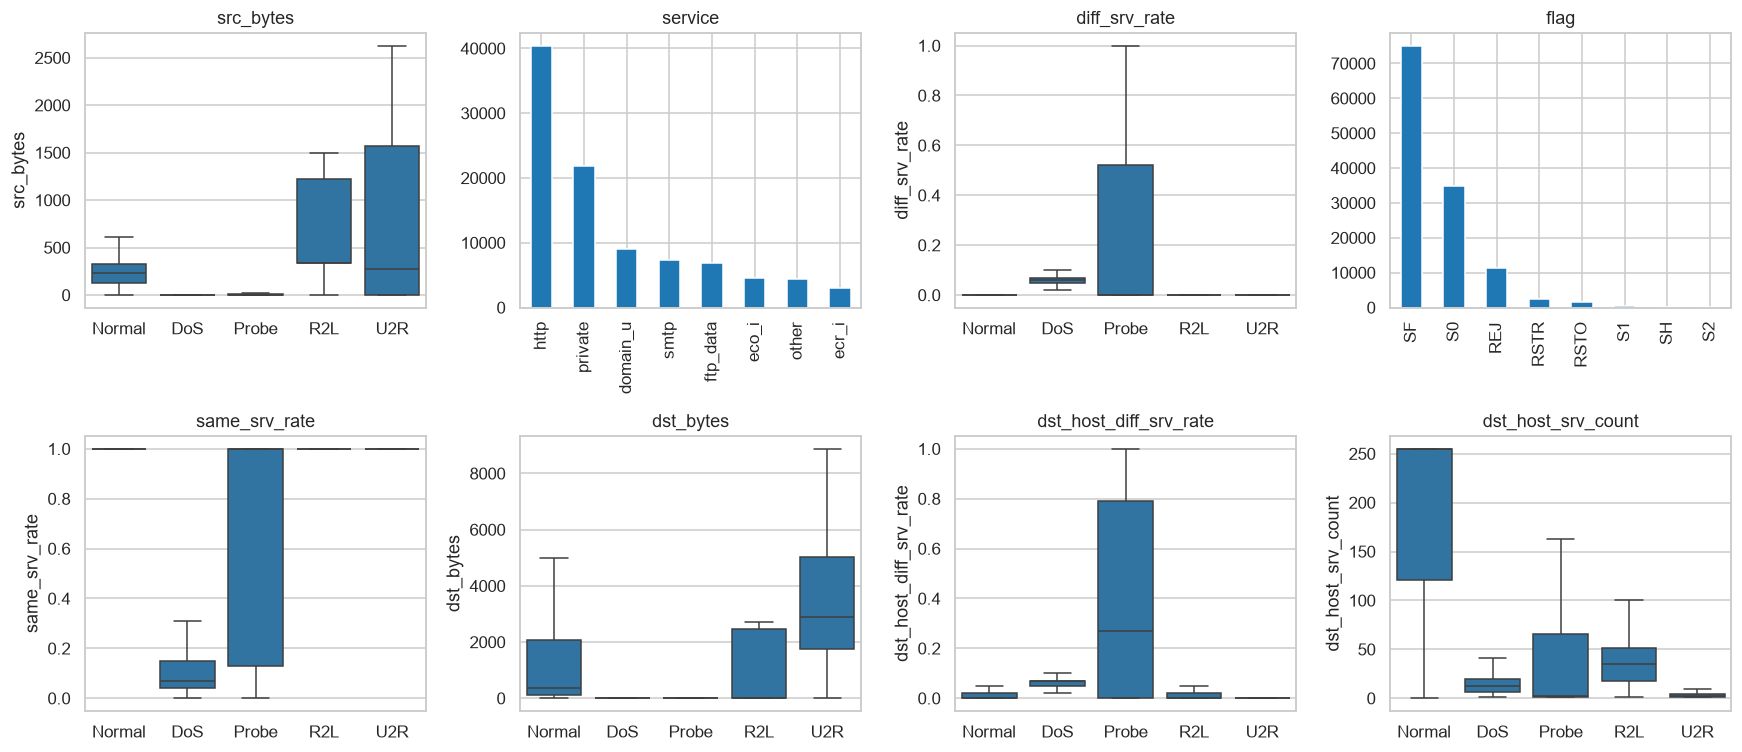

In [14]:
top = mi.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, top):
    if c in CATEGORICAL:
        train[c].value_counts().head(8).plot.bar(ax=ax)
    else:
        sns.boxplot(data=train, x="category", y=c, order=CLASSES, ax=ax, showfliers=False)
    ax.set_title(c); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG + "top_features_by_class.png", bbox_inches="tight"); plt.show()

## 6. Correlation and redundancy

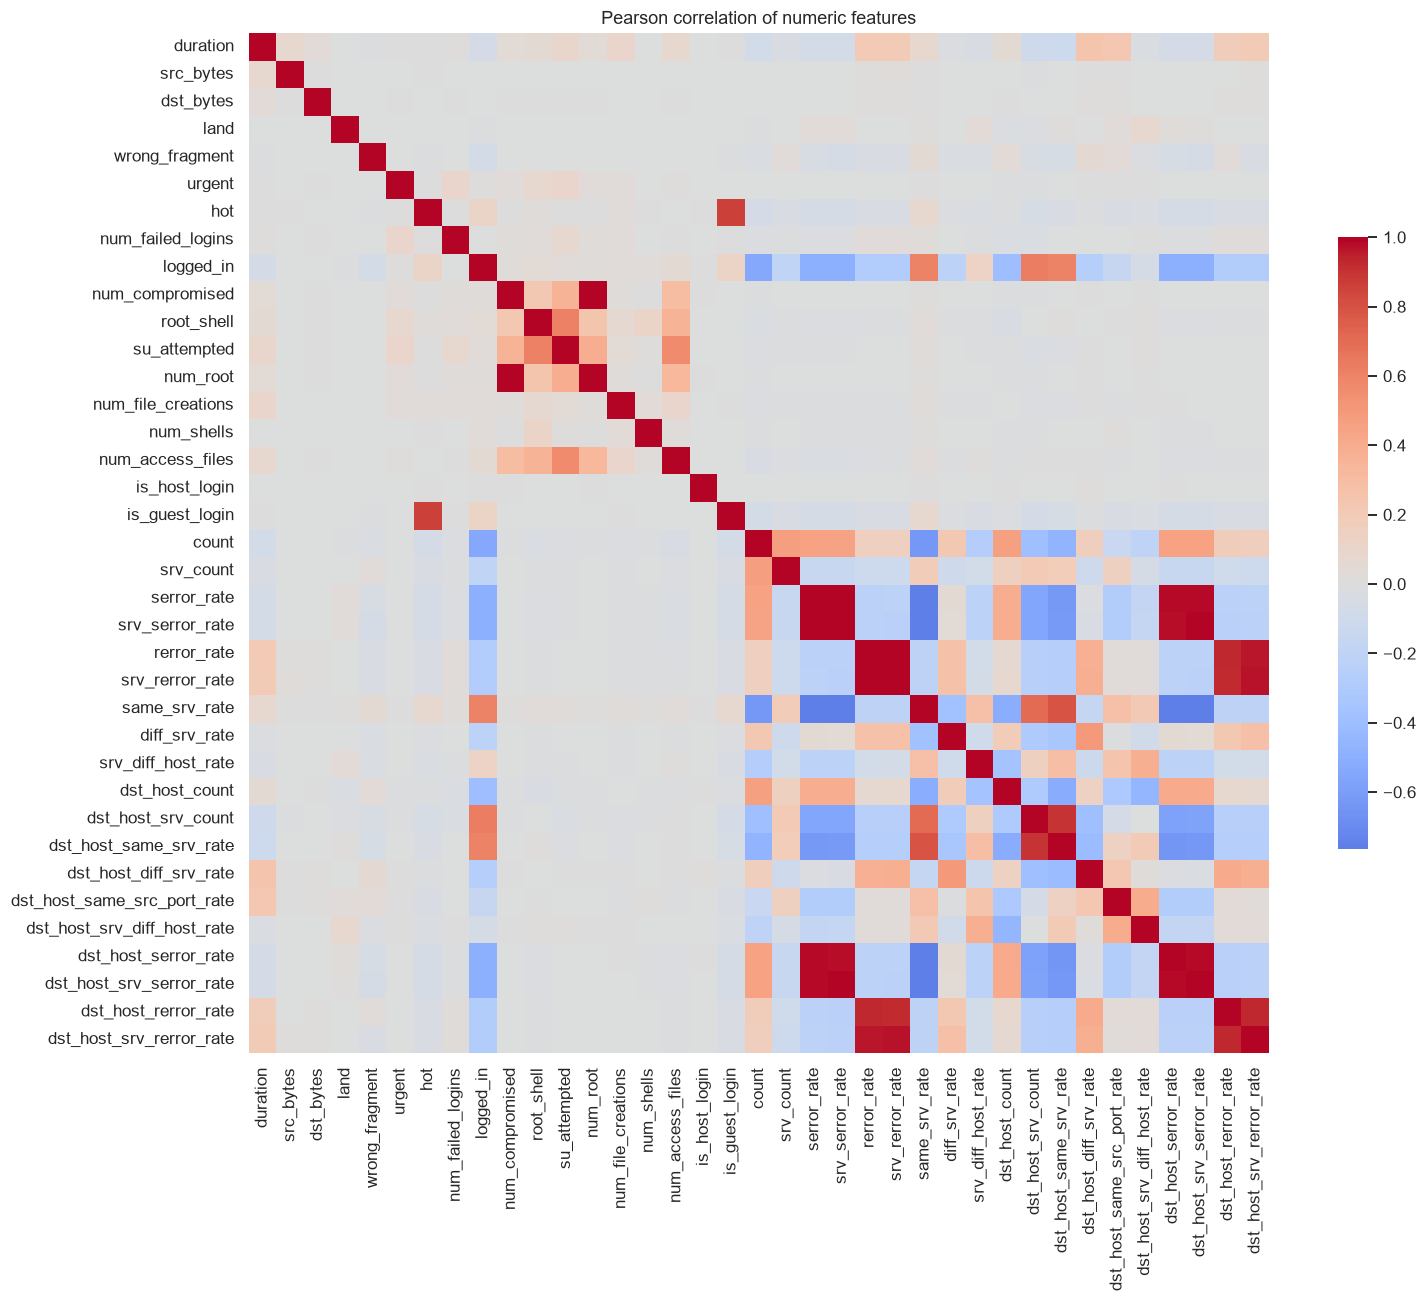

13 feature pairs with |r| > 0.9


,level_0,level_1,r
345,num_compromised,num_root,0.998833
761,serror_rate,srv_serror_rate,0.993289
837,rerror_rate,srv_rerror_rate,0.989008
811,srv_serror_rate,dst_host_srv_serror_rate,0.986252
1255,dst_host_serror_rate,dst_host_srv_serror_rate,0.985052
774,serror_rate,dst_host_srv_serror_rate,0.981139
773,serror_rate,dst_host_serror_rate,0.979373
810,srv_serror_rate,dst_host_serror_rate,0.977596
887,srv_rerror_rate,dst_host_srv_rerror_rate,0.970208
850,rerror_rate,dst_host_srv_rerror_rate,0.964449


In [15]:
num = [c for c in NUMERIC if train[c].nunique() > 1]
corr = train[num].corr()
plt.figure(figsize=(15, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .6}, xticklabels=True, yticklabels=True)
plt.title("Pearson correlation of numeric features"); plt.tight_layout()
plt.savefig(FIG + "correlation.png", bbox_inches="tight"); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().rename("r").reset_index()
pairs = pairs.loc[pairs.r.abs() > 0.9].sort_values("r", ascending=False)
print(f"{len(pairs)} feature pairs with |r| > 0.9")
pairs

## 7. Train vs test drift
The classic NSL-KDD trap: a model can score 99%+ on a random train split and much lower on `KDDTest+`. Two checks:

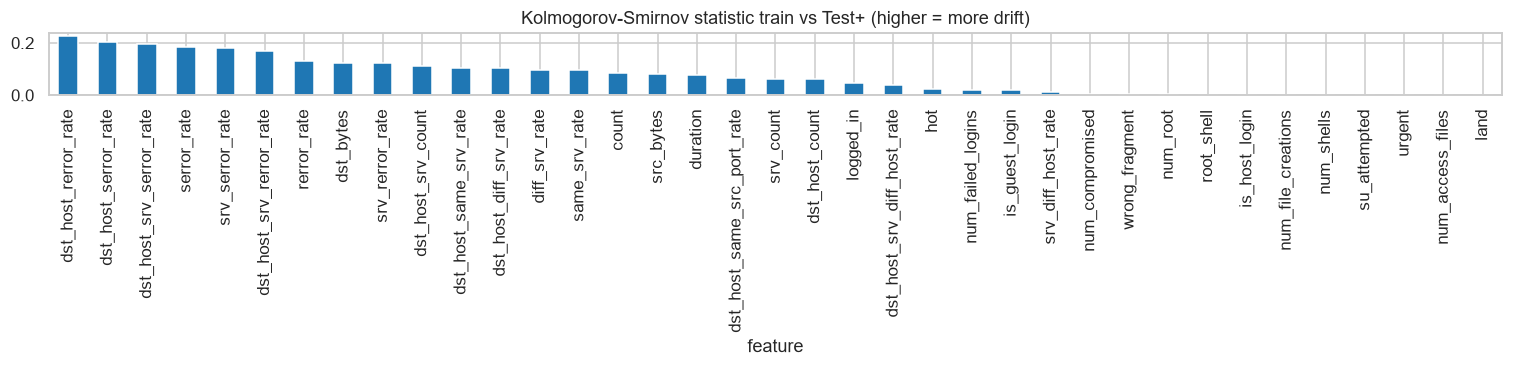

,KS,p
feature,,
dst_host_rerror_rate,0.2260,0.0
dst_host_serror_rate,0.2025,0.0
dst_host_srv_serror_rate,0.1968,0.0
serror_rate,0.1854,0.0
srv_serror_rate,0.1814,0.0
dst_host_srv_rerror_rate,0.1680,0.0
rerror_rate,0.1303,0.0
dst_bytes,0.1241,0.0
srv_rerror_rate,0.1236,0.0


In [16]:
ks = pd.DataFrame([(c, *ks_2samp(train[c], test[c])) for c in num], columns=["feature", "KS", "p"]).set_index("feature").sort_values("KS", ascending=False)
fig, ax = plt.subplots(figsize=(14, 3.5))
ks.KS.plot.bar(ax=ax); ax.set_title("Kolmogorov-Smirnov statistic train vs Test+ (higher = more drift)")
plt.tight_layout(); plt.savefig(FIG + "drift_ks.png", bbox_inches="tight"); plt.show()
ks.head(10).round(4)

In [17]:
# Adversarial validation: can a model tell train rows from test rows?
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
both = pd.concat([train[FEATURES].assign(is_test=0), test[FEATURES].assign(is_test=1)], ignore_index=True)
for c in CATEGORICAL:
    both[c] = both[c].astype("category").cat.codes
rf = RandomForestClassifier(200, n_jobs=-1, random_state=0, class_weight="balanced", min_samples_leaf=5)
auc = cross_val_score(rf, both[FEATURES], both.is_test, cv=3, scoring="roc_auc").mean()
print(f"Adversarial validation AUC: {auc:.3f}  (0.5 = identical distributions, 1.0 = fully separable)")
rf.fit(both[FEATURES], both.is_test)
pd.Series(rf.feature_importances_, FEATURES).sort_values(ascending=False).head(10).round(4)

Adversarial validation AUC: 0.912  (0.5 = identical distributions, 1.0 = fully separable)


src_bytes                      0.0776
dst_host_diff_srv_rate         0.0730
count                          0.0680
service                        0.0628
dst_host_srv_count             0.0621
dst_host_rerror_rate           0.0619
dst_bytes                      0.0574
dst_host_same_src_port_rate    0.0519
dst_host_same_srv_rate         0.0508
dst_host_serror_rate           0.0457
dtype: float64

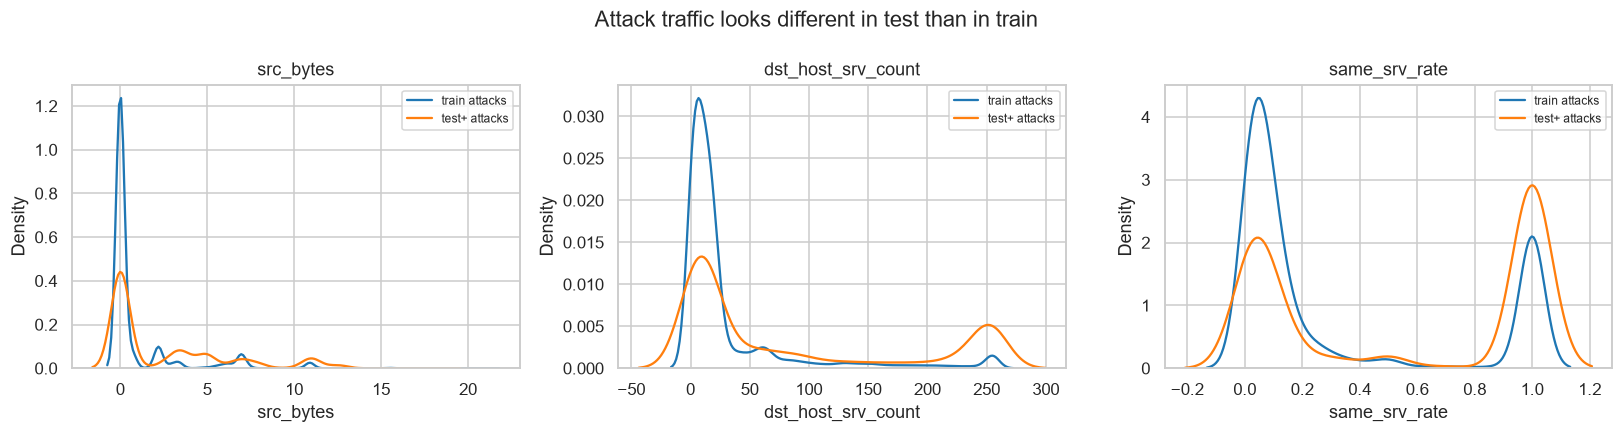

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["src_bytes", "dst_host_srv_count", "same_srv_rate"]):
    f = np.log1p if "bytes" in c else (lambda s: s)
    for name, df in [("train", train), ("test+", test)]:
        sns.kdeplot(f(df.loc[df.is_attack == 1, c]), ax=ax, label=f"{name} attacks", warn_singular=False)
    ax.set_title(c); ax.legend(fontsize=8)
plt.suptitle("Attack traffic looks different in test than in train"); plt.tight_layout(); plt.show()

## 8. Low-dimensional view (PCA)

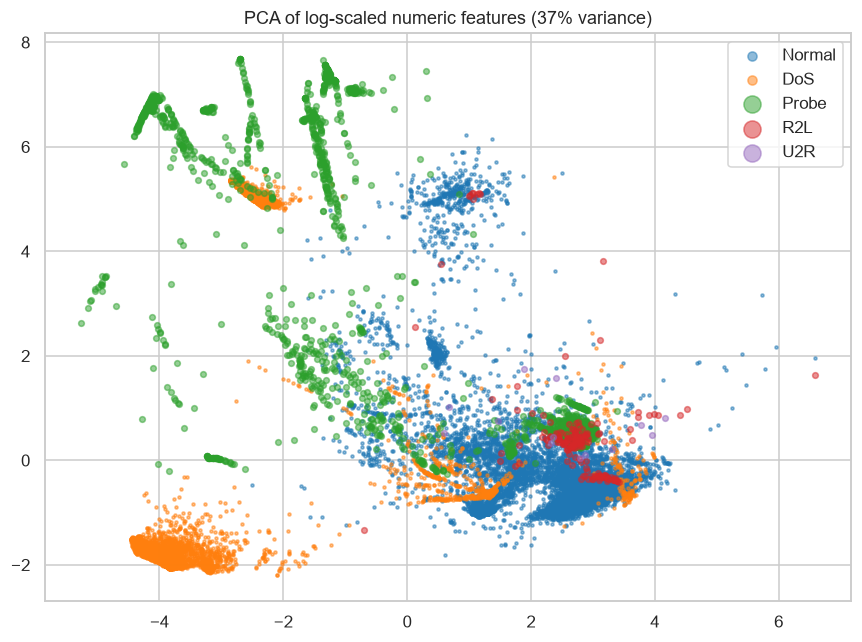

In [19]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
s = train.sample(20000, random_state=0)
Z = np.log1p(s[num].clip(lower=0))
pc = PCA(2, random_state=0).fit(StandardScaler().fit_transform(Z))
P = pc.transform(StandardScaler().fit_transform(Z))
plt.figure(figsize=(8, 6))
for cat in CLASSES:
    m = (s.category == cat).values
    plt.scatter(P[m, 0], P[m, 1], s=4 if cat in ("Normal", "DoS") else 14, alpha=.5, label=cat)
plt.legend(markerscale=3); plt.title(f"PCA of log-scaled numeric features ({pc.explained_variance_ratio_.sum():.0%} variance)")
plt.tight_layout(); plt.savefig(FIG + "pca.png", bbox_inches="tight"); plt.show()

## 9. Key findings → decisions for feature engineering and modelling

| Finding | Evidence | Decision |
|---|---|---|
| Clean data: no missing values, only 16 duplicate rows | §1 | No imputation. Keep duplicates (too few to matter). |
| `num_outbound_cmds` is constant | §1 | Drop it. |
| Severe imbalance: U2R = 52 rows (0.04%), R2L = 995 (0.8%) | §2 | Class weights, macro-F1 / per-class recall as metrics, try oversampling. |
| **Test has 17 attack types not in train (~17% of Test+)**, and R2L jumps from 0.8% to 13% | §2 | Plain random CV is misleading. Validate with **leave-attack-type-out CV**. Tune the decision threshold for recall on unseen attacks. |
| Volume and count features are extremely skewed (skew up to 350) | §4 | `log1p` transform. Ratio features. |
| `flag`, `service`, error rates, `same_srv_rate` and byte counts carry the most signal | §3, §5 | Engineer flag groups, error-rate aggregates, byte ratios and service concentration. |
| Many rare services | §3 | One-hot with rare categories grouped (`min_frequency`). |
| Groups of near-duplicate rate features (r > 0.9) | §6 | Optional correlation pruning. Trees handle it; linear models benefit. |
| Strong train→test drift (adversarial AUC well above 0.5) | §7 | Prefer models that generalise: regularised boosting / ensembles. Report on Test+ and Test-21 separately. |